# Demo 1.2: OVReader: from which layer the next sub-task is in the residual stream

**Insight.** GoalScope (Demo 1) reads what the goal heads write. The next sub-task is already in the residual stream
before they write it, from about the layers where the goal heads sit, but only when it is read the way the goal heads
read it.

**Setup.** Demo 1's task: four sub-tasks, the code for the first three prefilled, the prompt stopped at `d =` of the
fourth. The same four pivots.

**Readout (OVReader).** Take the residual stream after layer L at a pivot. For each of the 122 goal heads, compute what
the head would write if it attended to that residual (through its value and output maps), and average these writes
into one vector. Steer the GoalScope probe and the empty C++ stub with it, as in Demo 1. If the LM judge finds that the
description or the C++ body matches the next sub-task, the residual after layer L already carries it. We do this for
19 layers, next to GoalScope on the goal heads' own output. A readable residual at layer L does not mean the sub-task
is computed at L: the heads' maps may lift a weak signal into a legible one.

**Paper.** App. `app:ovreader` (`fig:ovreader`, `fig:ov-by-pivot`).

Needs one 80 GB GPU (Qwen2.5-Coder-32B-Instruct in bf16). The executed outputs are saved in this file.

In [1]:
# repo root = first parent dir that contains src/
import os, sys
_d = os.getcwd()
while _d != '/' and not os.path.isdir(os.path.join(_d, 'src')):
    _d = os.path.dirname(_d)
sys.path.insert(0, _d); os.chdir(_d)
print('repo root:', _d)

# no progress bars: keeps tqdm / HF widget outputs out of the saved notebook
os.environ['TQDM_DISABLE'] = '1'
import functools, tqdm.std, tqdm.notebook, transformers, huggingface_hub
for _c in (tqdm.std.tqdm, tqdm.notebook.tqdm):   # tqdm.notebook ignores TQDM_DISABLE, so force disable=True
    _c.__init__ = functools.partialmethod(_c.__init__, disable=True)
transformers.utils.logging.disable_progress_bar()
transformers.utils.logging.set_verbosity_error()      # no generation-config warnings
huggingface_hub.utils.disable_progress_bars()

# colors as in Demo 4: the LM's own code green, GoalScope-steered output purple, pivot token yellow
from typing import Literal
ide_theme: Literal['dark', 'light'] = 'dark'
if ide_theme == 'dark':   # light shades; the task-span fill reuses the text color
    DST_C, PAT_C = 'sea_green3', 'plum2'
    DST_BG       = DST_C
    PIVOT_BG     = 'bright_yellow'
else:                     # the paper's colors (Figure 5)
    DST_C, PAT_C = '#38761d', '#5b277d'
    DST_BG       = '#d9ead3'
    PIVOT_BG     = '#ffe6b2'

repo root: /disk/u/arnab/Codes/Projects/goals


In [2]:
CUDA         = '7'
MODEL        = 'Qwen/Qwen2.5-Coder-32B-Instruct'
GOAL_HEADS   = 'head_sets/Qwen2.5-Coder-32B-Instruct/goal__lam20_thr0.9_band25-56.json'   # the 122 goal heads
SPEC_ID      = 'list[int]_python_016'   # Demo 1's task: 4 sub-tasks, the last one is next
OV_ALPHA     = 0.15         # OVReader steering strength
SKY_ALPHA    = 0.1          # GoalScope on the goal heads' own output (the reference), as in Demo 1
STEER_LAYERS = (35, 46)     # the probe is steered at layers 35..45
SEED         = 123

os.environ['CUDA_VISIBLE_DEVICES'] = CUDA

## Load the model
Qwen2.5-Coder-32B-Instruct, its 122 goal heads, and the OVReader built from their value and output maps.

In [3]:
import collections
import numpy as np
import torch
import matplotlib.pyplot as plt
from rich.console import Console
from rich.table import Table
from rich.text import Text
from rich.markup import escape

from src.models import ModelandTokenizer
from src.tokens import prepare_input
from src.utils import experiment_utils
from src.goals.head_sets import load_json_heads
from src.goals.goalscope import OVReader, apply_goalscope, _build_causality_prompt, CAUSAL_PREFIX
from scripts.evaluation.eval_goalscope import (
    DEFAULT_DATASET, ALL_DATATYPES, MAX_NEW_TOKENS, GEN_MAX_NEW_TOKENS,
    load_locked_datapoints, build_prompt, generate_completion, frontier_impl_span, pivot_positions, hard_eval,
)
from scripts.evaluation import ov_reader_io as ovio

console = Console(width=150, highlight=False)
torch.set_grad_enabled(False)
experiment_utils.set_seed(SEED)

mt = ModelandTokenizer(model_key=MODEL, dtype=torch.bfloat16, device_map={'': 0}, attn_implementation='eager')
heads = load_json_heads(GOAL_HEADS, mt.n_layer, mt.n_heads)
ov = OVReader(mt, heads)
PROBE_LAYERS = sorted(set(list(range(0, 37, 6)) + list(range(38, 56, 2)) + list(range(56, mt.n_layer, 4)) + [mt.n_layer - 1]))
print(f'goal heads: {len(heads)} (layers {min(l for l, _ in heads)}-{max(l for l, _ in heads)})')
print(f'probe layers: {PROBE_LAYERS}')

Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory: /disk/u/models


goal heads: 122 (layers 28-55)
probe layers: [0, 6, 12, 18, 24, 30, 36, 38, 40, 42, 44, 46, 48, 50, 52, 54, 56, 60, 63]


## 1. The task and the LM's own continuation
As in Demo 1: the next sub-task, (4), is highlighted, and the four pivots are in yellow. The LM then writes the line
on its own; the judge compares every readout against it.

In [4]:
datapoints, _ = load_locked_datapoints(DEFAULT_DATASET, ALL_DATATYPES)
inst = dict(datapoints)[SPEC_ID]
prompt, var = build_prompt(mt, inst)
completion = generate_completion(mt, prompt, GEN_MAX_NEW_TOKENS)
full_text = prompt + completion
impl_span = frontier_impl_span(prompt, completion, var)      # the line the LM writes for sub-task (4)
pivs = pivot_positions(mt, prompt, full_text, ovio.PIVOT_ORDER)
REPORTED_PIVOTS = ['prev_end', 'indent', 'var', 'eq']

def show_prompt(text, span, pivots, start_at):
    """the prompt from `start_at` on: `span` (chars) on DST_BG, pivot tokens on PIVOT_BG, the rest dim"""
    enc = prepare_input(prompts=text, tokenizer=mt, return_offsets_mapping=True)
    txt = Text()
    for i, (tid, (s, e)) in enumerate(zip(enc['input_ids'][0].tolist(), enc['offset_mapping'][0].tolist())):
        if e <= start_at: continue
        style = (f'bold black on {PIVOT_BG}' if i in pivots else
                 f'black on {DST_BG}' if span[0] <= s < span[1] else 'dim')
        txt.append(mt.tokenizer.decode([tid]), style=style)
    console.rule('the prompt'); console.print(txt)

i = prompt.index(inst.expected_next_desc)
next_line = (prompt.rfind('\n', 0, i) + 1, prompt.index('\n', i))
show_prompt(prompt, next_line, {pivs[p] for p in REPORTED_PIVOTS}, start_at=prompt.index('<|im_start|>user'))

console.rule(f'[bold {DST_C}]the LM writes the next line[/]')
console.print(f'[bold]continuation:[/]\n[grey50]{escape(prompt.rsplit(chr(10), 1)[-1])}[/][{DST_C}]{escape(completion.rstrip())}[/]')

───────────────────────────────────────────────────────────────────── the prompt ─────────────────────────────────────────────────────────────────────

<|im_start|>user
Write a Python program that implements a function `func` which, given a list of integers `nums`, computes in sequential order:
(1) the number of odd values
(2) the number of positive values
(3) whether the values are sorted in non-decreasing order
(4) whether any value appears more than once
<|im_end|>
<|im_start|>assistant
<code>
def func(nums: list[int]):
    a = sum(1 for x in nums if x % 2 != 0)
    b = sum(1 for x in nums if x > 0)
    c = all(nums[i] <= nums[i+1] for i in range(len(nums)-1))
    d =

──────────────────────────────────────────────────────────── the LM writes the next line ─────────────────────────────────────────────────────────────

continuation:
    d = len(nums) != len(set(nums))
    return a, b, c, d
</code>

## 2. Readouts after every layer
For each pivot, the residual after each of the 19 layers is read through the goal heads and verbalized, once with the
neutral probe (faithfulness) and once with the C++ stub (causality). GoalScope on the goal heads' own output is the
reference. This is the slow part of the notebook.

In [5]:
MODES = ['faithfulness', 'causality']
apos = sorted(set(pivs.values()))
reads = {}                                                   # (mode, pivot, layer | 'goalscope') -> readout
for mode in MODES:
    sky = {r['pos']: r['patched_gen'] for r in apply_goalscope(
        full_text, mt=mt, selected_heads=heads, strategy='additive_norm', steer_layer_range=STEER_LAYERS,
        alpha=SKY_ALPHA, n_steer_tokens='all', max_new_tokens=MAX_NEW_TOKENS, include_noncode=False,
        token_positions=apos, goalscope_prompt=_build_causality_prompt(mt) if mode == 'causality' else None)}
    for p, q in pivs.items():
        reads[mode, p, 'goalscope'] = sky.get(q, '')
        by_layer = ov.apply_probe_on_prompt(full_text, q, PROBE_LAYERS, mode=mode, steer_layers=list(range(*STEER_LAYERS)),
                                            max_new_tokens=MAX_NEW_TOKENS, alpha=OV_ALPHA)
        for L in PROBE_LAYERS:
            reads[mode, p, L] = by_layer.get(L, '')
print(len(reads), 'readouts')

200 readouts


## 3. Judge
The LM judge (Claude) grades each readout: YES when it describes (or, for the C++ stub, implements) the sub-task of
the line the LM wrote. First the `=` pivot, layer by layer.

In [6]:
prefix = {'faithfulness': '', 'causality': CAUSAL_PREFIX}
verd = {k: hard_eval(prefix[k[0]] + (ro or ''), impl_span, k[0])['verdict'] for k, ro in reads.items()}

V = lambda v: '[bold green]YES[/]' if v == 'YES' else f'[red]{v}[/]'
one = lambda s, n=70: escape(' '.join(s.split())[:n] + ('...' if len(' '.join(s.split())) > n else ''))
t = Table(title=f'the `=` pivot (next sub-task: {escape(inst.expected_next_desc)})', show_lines=False)
t.add_column('read from'); t.add_column('description (faithfulness)'); t.add_column(''); t.add_column('C++ body (causality)'); t.add_column('')
for L in PROBE_LAYERS + ['goalscope']:
    name = 'GoalScope (goal-head output)' if L == 'goalscope' else f'residual after layer {L}'
    t.add_row(name, f"[{PAT_C}]{one(reads['faithfulness', 'eq', L])}[/]", V(verd['faithfulness', 'eq', L]),
              f"[{PAT_C}]{one(reads['causality', 'eq', L], 50)}[/]", V(verd['causality', 'eq', L]))
console.print(t)

                                       the `=` pivot (next sub-task: whether any value appears more than once)                                        
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┓
┃ read from                    ┃ description (faithfulness)                     ┃         ┃ C++ body (causality)                           ┃         ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━┩
│ residual after layer 0       │ I'm not doing anything; I'm just defining a    │ NO_INFO │ return value; }                                │ NO      │
│                              │ variable to hold a value t...                  │         │                                                │         │
│ residual after layer 6       │ I'm not doing anything; I'm just checking if a │ NO      │ return value > 0; }                            │ NO      │
│                              │ value is less than or e...                     │         │                                                │         │
│ residual after layer 12      │ I'm checking for conditions related to the     │ NO_INFO │ return [value](auto param) { return value *    │ NO      │
│                              │ logic of the code, likely i...                 │         │ param;...                                      │         │
│ residual after layer 18      │ I'm calculating the difference between two     │ NO      │ return [value](){ return value; }; }           │ NO_INFO │
│                              │ values to find the greatest...                 │         │                                                │         │
│ residual after layer 24      │ I'm checking for data integrity and ensuring   │ NO_INFO │ return std::gcd(1, value); }                   │ NO      │
│                              │ the code is executing pro...                   │         │                                                │         │
│ residual after layer 30      │ I'm checking if the variable `data` is defined │ NO      │ return std::is_same<decltype(value),           │ NO      │
│                              │ and if it's a dictionar...                     │         │ bool>::value ...                               │         │
│ residual after layer 36      │ I'm checking if there are any duplicate        │ YES     │ return std::any_of(value.begin(), value.end(), │ YES     │
│                              │ elements in the list, specific...              │         │ [](...                                         │         │
│ residual after layer 38      │ I'm checking if there are any duplicate        │ YES     │ return std::any_of(begin(value), end(value),   │ YES     │
│                              │ elements in the list by conver...              │         │ [](au...                                       │         │
│ residual after layer 40      │ I'm checking if there are any duplicate        │ YES     │ return value != std::distance(value.begin(),   │ YES     │
│                              │ elements in the list by compar...              │         │ std::...                                       │         │
│ residual after layer 42      │ I'm identifying if there's any variable or     │ YES     │ return value.size() > std::set(value.begin(),  │ YES     │
│                              │ data structure that has mor...                 │         │ valu...                                        │         │
│ residual after layer 44      │ I'm checking if there's any element in the     │ YES     │ return value.size() > std::set(value.begin(),  │ YES     │
│                              │ list that has more than one...                 │         │ valu...                                        │         │
│ residual after layer 46      │ I'm identifying if there's any variable i

The whole grid: every layer × the four pivots, in both modes (green = YES), next to how many of the 122 goal heads sit
in each layer band.

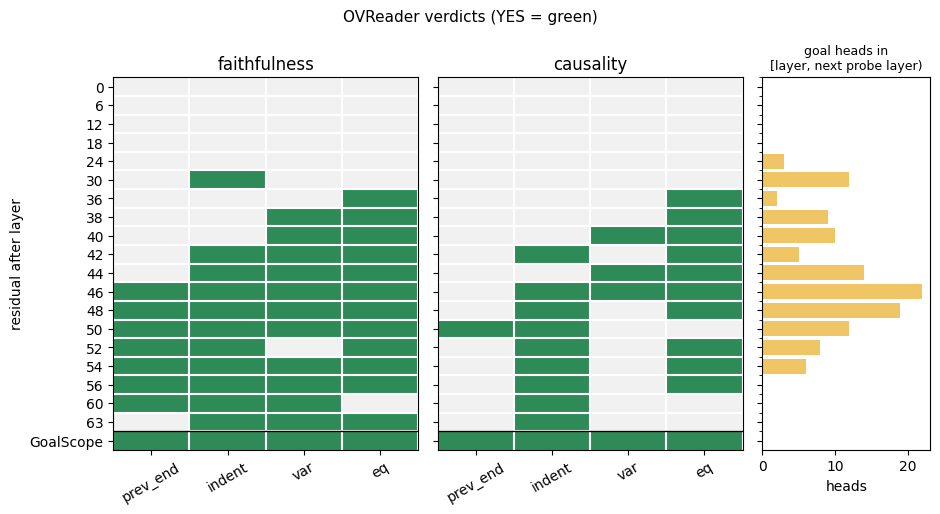

In [7]:
head_counts = collections.Counter(l for l, _ in heads)
fig, axes = plt.subplots(1, 3, figsize=(9.5, 5.2), gridspec_kw=dict(width_ratios=[4, 4, 2.2]), sharey=True)
y = np.arange(len(PROBE_LAYERS) + 1)
ylabels = [str(L) for L in PROBE_LAYERS] + ['GoalScope']
for ax, mode in zip(axes[:2], MODES):
    M = np.array([[verd[mode, p, L] == 'YES' for p in REPORTED_PIVOTS] for L in PROBE_LAYERS + ['goalscope']], float)
    ax.imshow(M, cmap=plt.matplotlib.colors.ListedColormap(['#f1f1f1', '#2e8b57']), vmin=0, vmax=1, aspect='auto')
    ax.set_xticks(range(4)); ax.set_xticklabels(REPORTED_PIVOTS, rotation=30)
    ax.set_title(mode); ax.axhline(len(PROBE_LAYERS) - 0.5, color='black', lw=1)
    ax.set_xticks(np.arange(-0.5, 4), minor=True); ax.set_yticks(y - 0.5, minor=True)
    ax.grid(which='minor', color='white', lw=1.5); ax.tick_params(which='minor', length=0)
axes[0].set_yticks(y); axes[0].set_yticklabels(ylabels); axes[0].set_ylabel('residual after layer')
counts = [sum(head_counts[l] for l in range(L, L2)) for L, L2 in zip(PROBE_LAYERS, PROBE_LAYERS[1:] + [mt.n_layer])] + [0]
axes[2].barh(y, counts, color='#E69F00', alpha=0.6)
axes[2].set_title('goal heads in\n[layer, next probe layer)', fontsize=9); axes[2].set_xlabel('heads')
fig.suptitle('OVReader verdicts (YES = green)', fontsize=11)
fig.tight_layout(); plt.show()

## What to expect
<img src="figures/01.2_ovreader_results.png" width="400" alt="OVReader readout score per layer, with the goal heads per layer (Figure 18 in the paper)">

Through the early layers, the readouts should say nothing about the next sub-task. From about the layers where the
goal heads sit (28–55), the residual reads out as the duplicate check, most clearly at the `=` pivot, and GoalScope
on the heads' own output is the ceiling. At the `=` pivot, averaged over the corpus's four datatypes, the judge
accepts 0% of the readouts after layer 0, 8% / 6% after layer 24, 95% / 88% after layer 48 and 67% / 66% after
layer 63 (faithfulness / causality), against 97% / 96% for GoalScope. See App. G and Figure 18 in the paper; Figure 19
breaks it down by pivot.